In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

In [ ]:
df = pd.read_csv("lab2_1_DS.csv")
print(df.columns.tolist())
print(df.head())
print(df.isna().sum())

['age', 'experience', 'income']
   age  experience  income
0   25           1   30450
1   30           3   35670
2   47           2   31580
3   32           5   40130
4   43          10   47830
age           0
experience    0
income        0
dtype: int64


In [ ]:
X = df[['age', 'experience']]
y = df['income']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
skm_linear = LinearRegression()
skm_linear.fit(X_train, y_train)

LinearRegression()

In [ ]:
skm_ridge = Ridge(alpha=1.0)
skm_ridge.fit(X_train, y_train)

Ridge()

In [ ]:
skm_lasso = Lasso(alpha=1.0, max_iter=10000)
skm_lasso.fit(X_train, y_train)

Lasso(max_iter=10000)

In [ ]:
skm_enet = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
skm_enet.fit(X_train, y_train)

ElasticNet(max_iter=10000)

In [ ]:
print("Linear: intercept", skm_linear.intercept_,"coef", skm_linear.coef_)
print("Ridge: intercept", skm_ridge.intercept_, "coef", skm_ridge.coef_)
print("Lasso: intercept", skm_lasso.intercept_,"coef", skm_lasso.coef_)
print("ElasticNet: intercept", skm_enet.intercept_,"coef", skm_enet.coef_)


Linear: intercept 31112.7517555032 coef [ -98.34696502 2168.24551409]
Ridge: intercept 31086.048098190928 coef [ -95.71378948 2156.66937884]
Lasso: intercept 31112.02384585302 coef [ -98.31380758 2168.15403364]
ElasticNet: intercept 30934.64056237125 coef [ -80.56777144 2089.77966528]


In [ ]:
y_pred_linear = skm_linear.predict(X_test)
y_pred_ridge = skm_ridge.predict(X_test)
y_pred_lasso = skm_lasso.predict(X_test)
y_pred_enet = skm_enet.predict(X_test)

In [ ]:
def metrics(y_true, y_pred):
  return(mean_absolute_error(y_true, y_pred), r2_score(y_true, y_pred), mean_absolute_percentage_error(y_true, y_pred) * 100)

In [ ]:
mae_lin, r2_lin, mape_lin = metrics(y_test, y_pred_linear)
mae_rid, r2_rid, mape_rid = metrics(y_test, y_pred_ridge)
mae_las, r2_las, mape_las = metrics(y_test, y_pred_lasso)
mae_en,  r2_en,  mape_en  = metrics(y_test, y_pred_enet)

In [ ]:
results_df = pd.DataFrame({
    'Model': ["Linear", 'Ridge', 'Lasso', 'ElasticNet'],
    'MAE' : [mae_lin, mae_rid, mae_las, mae_en],
    'R2' :  [r2_lin, r2_rid, r2_las, r2_en],
    'MAPE' : [mape_lin, mape_rid, mape_las, mape_en]
})

In [ ]:
print(results_df.to_string(index=False))

     Model        MAE       R2     MAPE
    Linear 834.057231 0.943829 2.206107
     Ridge 834.835707 0.944230 2.214116
     Lasso 834.003697 0.943831 2.205974
ElasticNet 839.667952 0.945667 2.261495


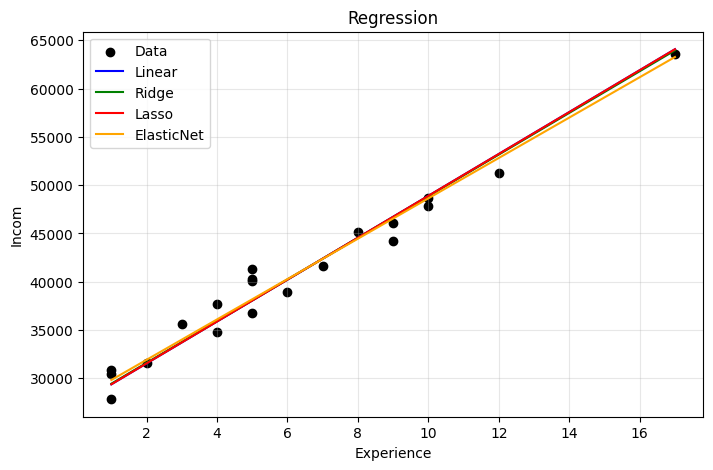

In [ ]:
age_mean = X['age'].mean()
exp_grid = np.linspace(X['experience'].min(), X['experience'].max(), 100)
X_grid = pd.DataFrame({'age': age_mean, 'experience': exp_grid})

plt.figure(figsize=(8, 5))
plt.scatter(X['experience'], y, color='black', label='Data')

plt.plot(exp_grid, skm_linear.predict(X_grid), color='blue',   label='Linear')
plt.plot(exp_grid, skm_ridge.predict(X_grid),  color='green',  label='Ridge')
plt.plot(exp_grid, skm_lasso.predict(X_grid),  color='red',    label='Lasso')
plt.plot(exp_grid, skm_enet.predict(X_grid),   color='orange', label='ElasticNet')

plt.xlabel('Experience')
plt.ylabel('Incom')
plt.title('Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
best = results_df.loc[results_df['R2'].idxmax()]
print("The best in R2:", best['Model'], "R2 =", round(best['R2'], 3))

The best in R2: ElasticNet R2 = 0.946
